In [2]:
#Import libraries and define Symbols
import sympy as smp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45, BDF
from scipy.optimize import direct, Bounds
import time
from control import lqr

## Parameters

$C_D$ - Coefficient of Drag 

$C_L$ - Coefficient of Lift 

$S$ - Reference Area 

$I_{yy}$ - Pitching Moment

$T$ - Thrust curve (to be turned into function of time)

$m$ - Mass of rocket (to be turned into function of time)

$g$ - Acceleration due to gravity

$d_{CoP}$ - Distance from CoM to Center of Pressure

$d_{Noz}$ - Distance from CoM to Nozzle

$\rho$ - Density of air

In [3]:
#Parameters

Cd = 0.1
Cl = 0.01
S = 0.01

Iyy = 0.2705

T = 100
m = 7
g = 9.8
dCoP = 0.5
dNoz = 0.7
rho = 1.225

## Ascent Control Matrices

$$

A = \begin{bmatrix}
0 & 1 & 0& 0\\
0 & -\frac{\rho S C_D}{2m} |\dot{z}|& -\frac{T}{m}&0 \\
0 & 0& 0& 1\\
0 &\frac{\rho S C_D d_{CoP}}{2 I_{yy}} |\dot{z}| & -\frac{\rho S C_D d_{CoP}}{2 I_{yy}} |\dot{z}| \dot{z}& 0\\
\end{bmatrix}

\\

B = \begin{bmatrix}
0 & 0\\
-\frac{T}{m} &0 \\
0 & 0\\
\frac{d_{Noz}T}{I_{yy}} & 0\\
\end{bmatrix}
$$

In [4]:
#Descent Control matrices
def A(t, dz):
    a = np.zeros([6,6])
    a[0,2] = 1
    a[1,3] = 1
    a[2,4] = -T/m
    a[4,5] = 1

    return a

def B(t, dz):
    b = np.zeros([6,2])
    b[2,0] = -T/m
    b[3,1] = -T/m
    b[5,0] = dNoz*T/Iyy
    return b

## Differential equation
$$

\begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    \ddot{x} \\
    \ddot{z} \\
    \dot{\theta} \\
    \ddot{\theta}
\end{bmatrix} 
= \begin{bmatrix}
    \dot{x} \\
    \dot{z} \\
    -\frac{\rho S C_D}{2m} \dot{x} \sqrt{\dot{x}^2 + \dot{z}^2} - \frac{(1-P)T}{m} \sin(\theta + \gamma)\\
    -\frac{\rho S C_D}{2m} \dot{z} \sqrt{\dot{x}^2 + \dot{z}^2} - \frac{(1-P)T}{m} \cos(\theta + \gamma)-g\\
    \dot{\theta} \\
    -\frac{\rho S C_D d_{CoP}}{2 I_{yy}} \left(\dot{x} \sqrt{\dot{x}^2 + \dot{z}^2} \cos(\theta)-\dot{z} \sqrt{\dot{x}^2 + \dot{z}^2} \sin(\theta)\right) + \frac{(1-P)T d_{Noz}}{I_{yy}} \sin(\gamma)\\
\end{bmatrix}

$$

In [5]:
#DiffEq Solver (BDF)
Q = np.diag([1,10,1,1,10,1])
R = np.diag([100,10000])

# Define the system of ODEs
def system(t, State):
    x, z, dx, dz, theta, dtheta = State

    #LQR to find K
    At = A(t, dz)
    Bt = B(t, dz)
    K, Ric, Eig = lqr(At, Bt, Q, R)

    #Set control parameters
    gamma, P = -K @ [x, z, dx, dz, theta, dtheta]
    #gamma = 0
    #P = 0

    ddx = -(rho*S*Cd)/(2*m) * dx * np.sqrt(dx**2 + dz**2) - (1-P)*T/m * np.sin(theta + gamma)
    ddz = -(rho*S*Cd)/(2*m) * dz * np.sqrt(dx**2 + dz**2) + (1-P)*T/m * np.cos(theta + gamma) - g
    ddtheta = (rho*S*Cd*dCoP)/(2*Iyy) * (dx *  np.sqrt(dx**2 + dz**2) * np.cos(theta) - dz *  np.sqrt(dx**2 + dz**2) * np.sin(theta)) + (1-P)*dNoz*T/Iyy * np.sin(gamma)
    return [dx, dz, ddx, ddz, dtheta, ddtheta]

# Initial conditions
State0 = [0,100,0,0,1,1]

# Time span
t_span = (0, 50)

#Solution Data
t_vals, State_vals = [], []


#End status (0=full run, 1=took too long, 2=crashed)
status = 0

#Start Solver
start_time = time.time()
solver = BDF(system, t_span[0], State0, t_span[1])
while solver.status == "running":
    #Step solver and save data
    solver.step()
    t_vals.append(solver.t)
    State_vals.append(solver.y.copy())

    #End conditions
    if time.time() - start_time > 1:   
        solver.status = "stopped"       
        status = 1
        break
    if (State_vals[-1][1] < 0):
        solver.status = "stopped"    
        status = 2
        break

#Timestamped data
State_vals = np.array(State_vals).T

Status: 0


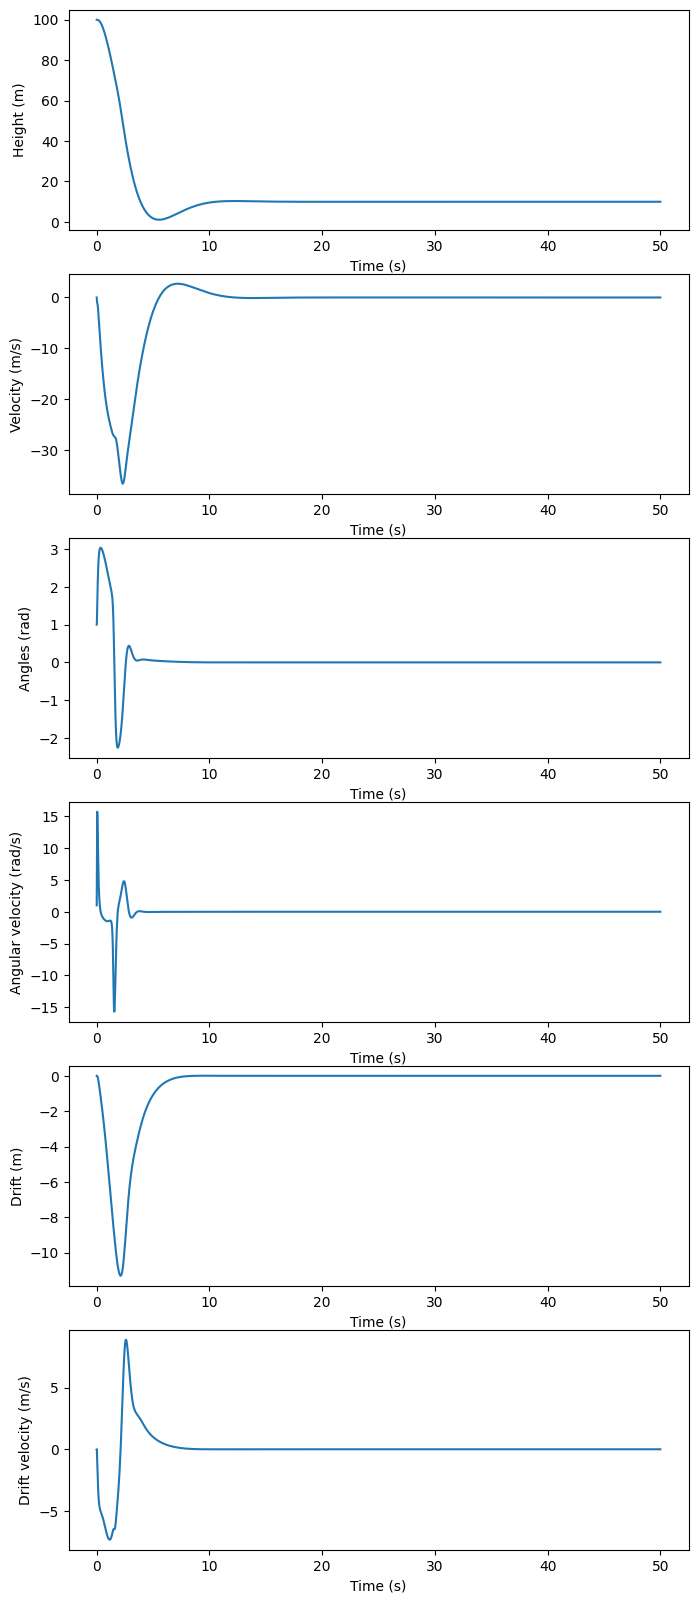

In [6]:
#Plot the trajectory
fig, ax = plt.subplots(nrows=6, ncols=1,figsize=(8, 20))
for i in range(6):
    ax[i].set_xlabel("Time (s)")

ax[0].plot(t_vals, State_vals[1])
ax[1].plot(t_vals, State_vals[3])
ax[2].plot(t_vals, State_vals[4])
ax[3].plot(t_vals, State_vals[5])
ax[4].plot(t_vals, State_vals[0])
ax[5].plot(t_vals, State_vals[2])

ax[0].set_ylabel("Height (m)")
ax[1].set_ylabel("Velocity (m/s)")
ax[2].set_ylabel("Angles (rad)")
ax[3].set_ylabel("Angular velocity (rad/s)")
ax[4].set_ylabel("Drift (m)")
ax[5].set_ylabel("Drift velocity (m/s)")

#Print status (0=full run, 1=took too long, 2=crashed)
print(f"Status: {status}")

#Show plots
plt.show()